<a href="https://colab.research.google.com/github/Hassanat718/Module-3-case-Exercise/blob/main/Module_3_Case_Exercise_1_(Jubilee_TRP3_Metocean_EDA_and_Seasonal_Analysis).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Case Exercise 1: Metocean EDA and Seasonal Analysis**

## Project Overview

This assessment focuses on Exploratory Data Analysis (EDA), statistical distribution fitting, seasonal analysis, and feature engineering using one year of hourly Jubilee TRP3 metocean observations.

## Objectives

1. Perform comprehensive exploratory data analysis.
2. Fit Weibull and Log-normal distributions to significant wave height (Hs) and peak wave period (Tp), respectively.
3. Examine relationships between metocean variables.
4. Investigate temporal patterns and seasonal variations.
5. Develop an Hs-Tp scatter diagram and current rose.
6. Engineer temporal, seasonal, rolling, and cumulative features.

## Offshore Asset Integrity Relevance

Metocean conditions influence offshore structural loading, fatigue accumulation, operational limits, and the integrity of subsea infrastructure.

Understanding these environmental conditions supports offshore asset integrity assessment and monitoring.

## Expected Deliverables

- Completed Jupyter Notebook.
- Enriched CSV containing original observations and at least 30 engineered features.
- Both deliverables committed to GitHub.


##**Importing Required Libraries**

In this section, we import the Python libraries required
for data manipulation, numerical computation and
visualization.

- Pandas: Data manipulation and analysis.
- NumPy: Numerical computations.
- Matplotlib: Data visualization.
- Seaborn: Statistical visualization.

In [1]:
# Import the libraries required for data analysis,
# statistical modelling, and visualisation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose

# Configure visualisation settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")


Libraries imported successfully.



## **Loading and Inspecting the Dataset**

In this section, we will load the Jubilee TRP3 metocean dataset from its CSV file and inspect its structure.

The initial inspection will help us identify:
- Available metocean parameters.
- Number of observations and variables.
- Data types of each variable.
- Missing values.
- Whether the dataset contains the expected hourly observations.

Understanding the dataset structure is essential before performing statistical analysis and developing features for offshore asset integrity assessment.


In [2]:
# Import the file upload utility (Google Colab)
from google.colab import files

# Upload the Jubilee TRP3 CSV file
uploaded = files.upload()

# Identify the uploaded CSV filename
file_name = next(iter(uploaded))

# Load the CSV dataset into a Pandas DataFrame
df = pd.read_csv(file_name)

# Display the first five observations
df.head()


Saving Jubilee_TRP3_Metocean.csv to Jubilee_TRP3_Metocean.csv


,timestamp,Hs,season,Tp,MWD,Uc,CD,U10,SST,d
0,2025-01-01 00:00:00,1.524854,Dry,14.580621,202.472407,0.653218,236.744134,4.375462,24.497448,838
1,2025-01-01 01:00:00,1.260000,Dry,14.278740,237.042858,0.470964,295.741132,6.452242,29.514028,838
2,2025-01-01 02:00:00,1.260000,Dry,13.938506,223.919637,0.575957,285.291665,5.008258,25.771982,838
3,2025-01-01 03:00:00,1.454204,Dry,14.137886,215.919509,0.563988,281.502265,3.932616,28.473673,838
4,2025-01-01 04:00:00,1.338419,Dry,13.680172,189.361118,0.639553,31.909525,4.320759,29.308808,838



### **Dataset Structure and Data Types**

We will examine the dimensions, column names, and data types of the dataset.

This helps us distinguish numerical variables from categorical and temporal variables before conducting statistical analysis.

Correct identification of variable types is important because metocean parameters such as wave height, current speed, and wind speed require numerical analysis, while timestamps and seasonal classifications require separate treatment.


In [3]:
# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display all column names
print("\nDataset columns:")
print(df.columns.tolist())

# Inspect column data types and non-null counts
print("\nDataset information:")
df.info()


Dataset dimensions: (8760, 10)

Dataset columns:
['timestamp', 'Hs', 'season', 'Tp', 'MWD', 'Uc', 'CD', 'U10', 'SST', 'd']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  8760 non-null   object 
 1   Hs         8760 non-null   float64
 2   season     8760 non-null   object 
 3   Tp         8760 non-null   float64
 4   MWD        8760 non-null   float64
 5   Uc         8760 non-null   float64
 6   CD         8760 non-null   float64
 7   U10        8760 non-null   float64
 8   SST        8760 non-null   float64
 9   d          8760 non-null   int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 684.5+ KB


8,760 observations correspond to 365 days × 24 hours. This is consistent with one year of hourly observations.

However, we haven't yet confirmed that every timestamp is unique and that there are no missing hours.

Also, all 8,760 observations have non-null values. That is encouraging, but non-null values do not automatically mean the data are valid.


## **Data Quality Assessment**

In this section, we will assess the completeness and consistency of the hourly metocean dataset.

The checks will include:

- Missing values.
- Duplicate observations.
- Timestamp continuity and hourly frequency.
- Descriptive statistics and possible abnormal values.

These checks help establish whether the dataset is suitable for subsequent statistical analysis, seasonal modelling, and offshore environmental loading assessment.


In [4]:
# Calculate the number of missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Combine the results into a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Display the missing value summary
missing_summary


,Missing Values,Missing Percentage (%)
timestamp,0,0.0
Hs,0,0.0
season,0,0.0
Tp,0,0.0
MWD,0,0.0
Uc,0,0.0
CD,0,0.0
U10,0,0.0
SST,0,0.0
d,0,0.0


# **Interpretation**
This means we don't currently need to perform missing-value imputation.

For our offshore asset integrity assessment, this is important because missing wave, wind or current measurements could affect subsequent environmental loading analysis.

However, remember: complete data does not necessarily mean clean data. We still need to check duplicates, timestamp continuity and physically unrealistic values.


### **Duplicate Observation Check**

We will check for duplicate rows in the dataset.

Duplicate observations can distort statistical distributions, correlation analysis, and time-series calculations.

Identifying and investigating duplicates helps maintain the reliability of our metocean analysis.


In [5]:
# Count the number of completely duplicated rows
duplicate_rows = df.duplicated().sum()

# Display the result
print("Number of duplicate rows:", duplicate_rows)


Number of duplicate rows: 0



### **Timestamp Continuity Check**

We will convert the timestamp column into a proper datetime format and examine the time intervals between consecutive observations.

The dataset is expected to contain hourly observations throughout the year.

This check is particularly important because rolling statistics and cumulative environmental exposure features depend on correctly ordered and consistently spaced observations.


In [6]:
# Convert the timestamp column to datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Calculate the time difference between consecutive observations
time_difference = df["timestamp"].diff()

# Count the different time intervals
interval_counts = time_difference.value_counts()

# Display the most common time intervals
print("Time interval distribution:")
print(interval_counts)

# Check the earliest and latest timestamps
print("\nFirst timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

# Check whether timestamps are in chronological order
print("\nChronologically ordered:", df["timestamp"].is_monotonic_increasing)


Time interval distribution:
timestamp
0 days 01:00:00    8759
Name: count, dtype: int64

First timestamp: 2025-01-01 00:00:00
Last timestamp: 2025-12-31 23:00:00

Chronologically ordered: True



### **Preliminary Physical Range Assessment**

We will examine the minimum, maximum, mean, and quartile values of the numerical metocean variables.

This will help identify potentially abnormal observations and values that may require further investigation.

Physical range checks are important in offshore asset integrity because unrealistic environmental measurements can distort loading assessments and subsequent statistical models.


In [7]:

# Select numerical columns for preliminary statistical assessment
numerical_columns = df.select_dtypes(include=np.number).columns

# Generate descriptive statistics
descriptive_stats = df[numerical_columns].describe()

# Display the results
descriptive_stats


,Hs,Tp,MWD,Uc,CD,U10,SST,d
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.0
mean,1.654299,11.329474,209.636492,0.727435,179.554992,5.767170,27.009796,838.0
std,0.295883,2.099268,17.304380,0.214120,103.816900,2.234604,1.729393,0.0
min,1.260000,8.000000,180.000698,0.300000,0.001993,0.553362,24.001621,838.0
25%,1.384252,9.572551,194.600550,0.561783,89.082517,3.939129,25.512517,838.0
50%,1.640887,11.003234,209.514120,0.709965,180.215552,5.490415,27.040335,838.0
75%,1.886715,13.209491,224.499127,0.883674,268.390298,7.503978,28.525099,838.0
max,2.713772,16.200000,239.983060,1.467204,359.924174,13.203483,29.998988,838.0



## **Exploratory Data Analysis (EDA)**

Exploratory Data Analysis is used to understand the characteristics, distributions, and relationships within the metocean dataset.

### **Descriptive Statistics**

We will calculate summary statistics for the numerical metocean parameters, including the mean, standard deviation, minimum, maximum, and quartiles.

These statistics provide an initial understanding of the environmental conditions influencing offshore structures and subsea infrastructure.


In [8]:

# Select numerical metocean variables
metocean_variables = ["Hs", "Tp", "MWD", "Uc", "CD", "U10", "SST"]

# Calculate descriptive statistics
eda_summary = df[metocean_variables].describe()

# Display the summary statistics
eda_summary


,Hs,Tp,MWD,Uc,CD,U10,SST
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,1.654299,11.329474,209.636492,0.727435,179.554992,5.767170,27.009796
std,0.295883,2.099268,17.304380,0.214120,103.816900,2.234604,1.729393
min,1.260000,8.000000,180.000698,0.300000,0.001993,0.553362,24.001621
25%,1.384252,9.572551,194.600550,0.561783,89.082517,3.939129,25.512517
50%,1.640887,11.003234,209.514120,0.709965,180.215552,5.490415,27.040335
75%,1.886715,13.209491,224.499127,0.883674,268.390298,7.503978,28.525099
max,2.713772,16.200000,239.983060,1.467204,359.924174,13.203483,29.998988



##**Weibull Distribution Fitting for Significant Wave Height (Hs)**

The Weibull distribution will be fitted to the significant wave height (Hs) observations using Maximum Likelihood Estimation (MLE).

The fitted distribution will be used to examine the probability characteristics of wave height and assess how well the theoretical distribution represents the observed metocean conditions.

This is relevant to offshore asset integrity because wave height is an important environmental parameter influencing structural loading and fatigue exposure.


In [9]:
# Extract significant wave height observations
hs_data = df["Hs"]

# Fit a two-parameter Weibull distribution using Maximum Likelihood Estimation
# The location parameter is fixed at zero.
weibull_shape, weibull_location, weibull_scale = stats.weibull_min.fit(
    hs_data,
    floc=0
)

# Display the fitted distribution parameters
print("Weibull Distribution Parameters")
print("--------------------------------")
print(f"Shape parameter (k): {weibull_shape:.4f}")
print(f"Location parameter: {weibull_location:.4f}")
print(f"Scale parameter (λ): {weibull_scale:.4f}")


Weibull Distribution Parameters
--------------------------------
Shape parameter (k): 6.0230
Location parameter: 0.0000
Scale parameter (λ): 1.7800



### **Visualisation of the Fitted Weibull Distribution**

We will plot a histogram of the observed significant wave heights and overlay the fitted Weibull probability density function (PDF).

The comparison will help us visually assess how closely the theoretical Weibull distribution represents the observed wave-height data.

A good fit would indicate that the Weibull distribution provides a reasonable statistical representation of the observed wave-height conditions.


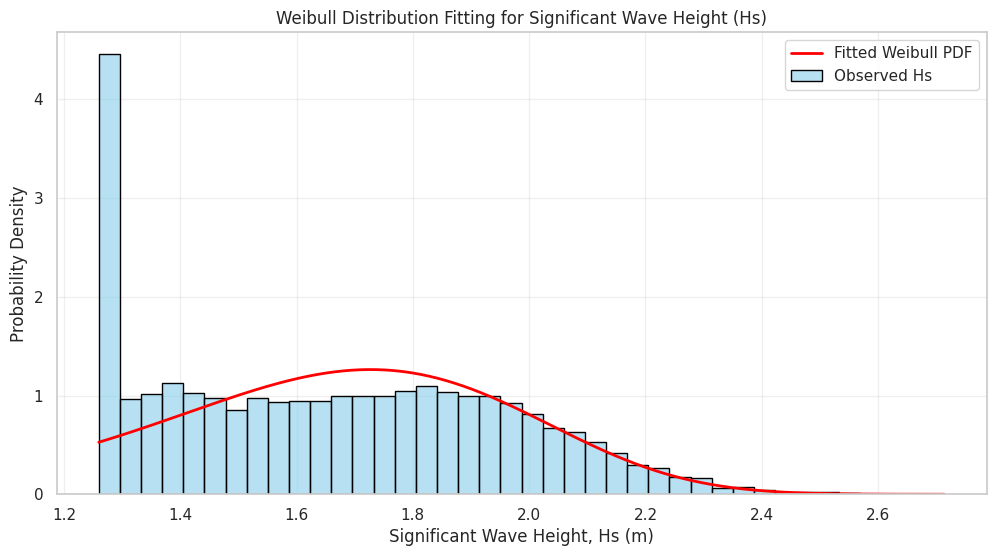

In [10]:

# Generate a range of Hs values for the theoretical Weibull curve
hs_range = np.linspace(hs_data.min(), hs_data.max(), 500)

# Calculate the fitted Weibull probability density
weibull_pdf = stats.weibull_min.pdf(
    hs_range,
    weibull_shape,
    loc=weibull_location,
    scale=weibull_scale
)

# Plot the observed Hs distribution
plt.figure(figsize=(12, 6))

sns.histplot(
    hs_data,
    bins=40,
    stat="density",
    color="skyblue",
    edgecolor="black",
    alpha=0.6,
    label="Observed Hs"
)

# Overlay the fitted Weibull distribution
plt.plot(
    hs_range,
    weibull_pdf,
    color="red",
    linewidth=2,
    label="Fitted Weibull PDF"
)

# Add plot labels and title
plt.title("Weibull Distribution Fitting for Significant Wave Height (Hs)")
plt.xlabel("Significant Wave Height, Hs (m)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



### **Statistical Goodness-of-Fit Assessment**

The Kolmogorov–Smirnov (K-S) test will be used to evaluate the agreement between the observed significant wave-height distribution and the fitted Weibull distribution.

The test measures the maximum difference between the empirical cumulative distribution function (ECDF) and the theoretical cumulative distribution function (CDF).

A smaller K-S statistic indicates closer agreement.

The p-value will be examined as part of the goodness-of-fit assessment.


In [11]:

# Perform the Kolmogorov-Smirnov goodness-of-fit test
ks_statistic, ks_pvalue = stats.kstest(
    hs_data,
    "weibull_min",
    args=(weibull_shape, weibull_location, weibull_scale)
)

# Display the test results
print("Weibull Goodness-of-Fit Test")
print("----------------------------")
print(f"K-S Statistic: {ks_statistic:.4f}")
print(f"P-value: {ks_pvalue:.6f}")

# Interpret the p-value using a 5% significance level
if ks_pvalue < 0.05:
    print("\nThe test rejects the null hypothesis at the 5% significance level.")
else:
    print("\nThe test does not reject the null hypothesis at the 5% significance level.")


Weibull Goodness-of-Fit Test
----------------------------
K-S Statistic: 0.1173
P-value: 0.000000

The test rejects the null hypothesis at the 5% significance level.



## **Log-normal Distribution Fitting for Peak Wave Period (Tp**)

A log-normal distribution will be fitted to the peak wave period (Tp) observations using Maximum Likelihood Estimation (MLE).

The fitted distribution will be used to examine the probability characteristics of wave periods and assess how well the theoretical distribution represents the observed data.

This analysis is relevant to offshore asset integrity because wave period influences wave kinematics and the dynamic response of offshore structures.


In [12]:
# Extract peak wave period observations
tp_data = df["Tp"]

# Fit a log-normal distribution using Maximum Likelihood Estimation
# Fix the location parameter at zero for a two-parameter model.
lognorm_shape, lognorm_location, lognorm_scale = stats.lognorm.fit(
    tp_data,
    floc=0
)

# Display the fitted distribution parameters
print("Log-normal Distribution Parameters")
print("-----------------------------------")
print(f"Shape parameter (sigma): {lognorm_shape:.4f}")
print(f"Location parameter: {lognorm_location:.4f}")
print(f"Scale parameter: {lognorm_scale:.4f}")


Log-normal Distribution Parameters
-----------------------------------
Shape parameter (sigma): 0.1867
Location parameter: 0.0000
Scale parameter: 11.1350


### **Visualisation of the Fitted Log-normal Distribution**

We will plot a histogram of the observed peak wave periods and overlay the fitted log-normal probability density function (PDF).

This comparison will help us visually evaluate how closely the theoretical log-normal distribution represents the observed wave-period data.


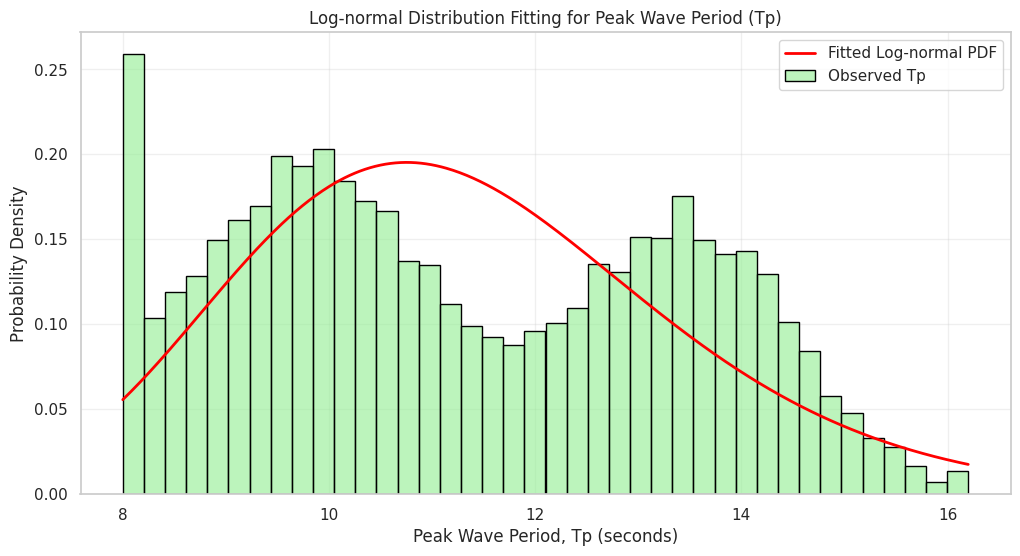

In [13]:

# Generate a range of Tp values for the theoretical curve
tp_range = np.linspace(tp_data.min(), tp_data.max(), 500)

# Calculate the fitted log-normal probability density
lognorm_pdf = stats.lognorm.pdf(
    tp_range,
    lognorm_shape,
    loc=lognorm_location,
    scale=lognorm_scale
)

# Plot the observed Tp distribution
plt.figure(figsize=(12, 6))

sns.histplot(
    tp_data,
    bins=40,
    stat="density",
    color="lightgreen",
    edgecolor="black",
    alpha=0.6,
    label="Observed Tp"
)

# Overlay the fitted log-normal distribution
plt.plot(
    tp_range,
    lognorm_pdf,
    color="red",
    linewidth=2,
    label="Fitted Log-normal PDF"
)

# Add plot labels and title
plt.title("Log-normal Distribution Fitting for Peak Wave Period (Tp)")
plt.xlabel("Peak Wave Period, Tp (seconds)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### **Statistical Goodness-of-Fit Test for Tp**

The Kolmogorov-Smirnov (K-S) test compares the observed distribution of peak wave period (Tp) with the fitted log-normal distribution.

- Null hypothesis (H0): The observed Tp data follows the fitted log-normal distribution.
- Alternative hypothesis (H1): The observed Tp data does not follow the fitted log-normal distribution.

We use a 5% significance level (0.05).

If the p-value is below 0.05, we reject the null hypothesis.

In [14]:
# Perform the Kolmogorov-Smirnov goodness-of-fit test
tp_ks_statistic, tp_ks_pvalue = stats.kstest(
    tp_data,
    "lognorm",
    args=(lognorm_shape, lognorm_location, lognorm_scale)
)

# Display the test results
print("Log-normal Goodness-of-Fit Test")
print("--------------------------------")
print(f"K-S Statistic: {tp_ks_statistic:.4f}")
print(f"P-value: {tp_ks_pvalue:.6f}")

# Interpret the result at a 5% significance level
if tp_ks_pvalue < 0.05:
    print("\nThe test rejects the null hypothesis at the 5% significance level.")
else:
    print("\nThe test does not reject the null hypothesis at the 5% significance level.")

Log-normal Goodness-of-Fit Test
--------------------------------
K-S Statistic: 0.0838
P-value: 0.000000

The test rejects the null hypothesis at the 5% significance level.


### **Pearson Correlation Analysis**

The Pearson correlation coefficient is used to examine the strength and direction of linear relationships between the selected metocean variables.

Directional variables (MWD and CD) are excluded from this initial matrix because angular measurements require circular statistical treatment.

In [15]:
# Select continuous, non-directional metocean variables
correlation_variables = ["Hs", "Tp", "Uc", "U10", "SST"]

# Calculate the Pearson correlation matrix
correlation_matrix = df[correlation_variables].corr(method="pearson")

# Display the correlation values
correlation_matrix

,Hs,Tp,Uc,U10,SST
Hs,1.000000,-0.652220,0.526340,0.572849,-0.008861
Tp,-0.652220,1.000000,-0.590272,-0.629891,0.000003
Uc,0.526340,-0.590272,1.000000,0.495562,0.006450
U10,0.572849,-0.629891,0.495562,1.000000,0.002807
SST,-0.008861,0.000003,0.006450,0.002807,1.000000


### **Correlation Heatmap**

A heatmap provides a visual representation of the correlation matrix.

- Positive correlations are represented by positive values.
- Negative correlations are represented by negative values.
- Values closer to +1 or -1 indicate stronger linear relationships.
- Values closer to zero indicate weaker linear relationships.

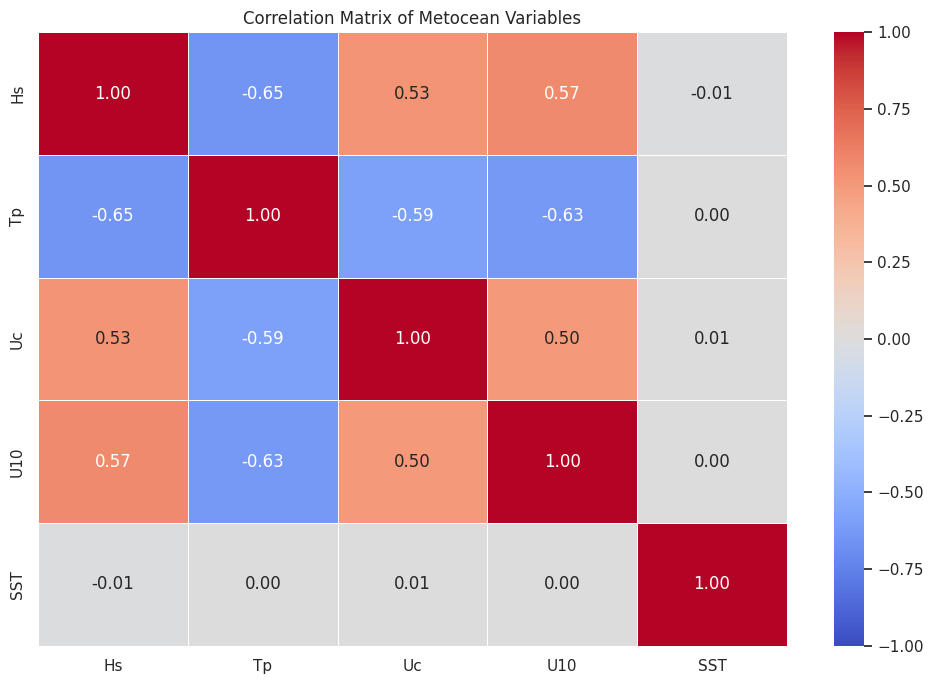

In [16]:
# Plot the correlation matrix as a heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Metocean Variables")
plt.tight_layout()
plt.show()

## **Metocean Time-Series Analysis**

Time-series analysis examines how metocean conditions vary over the observation period.

This helps identify:
- Temporal fluctuations in environmental conditions.
- Periods of relatively high or low environmental loading.
- Potential recurring patterns and seasonal variations.

These patterns provide useful context for offshore asset integrity assessments.

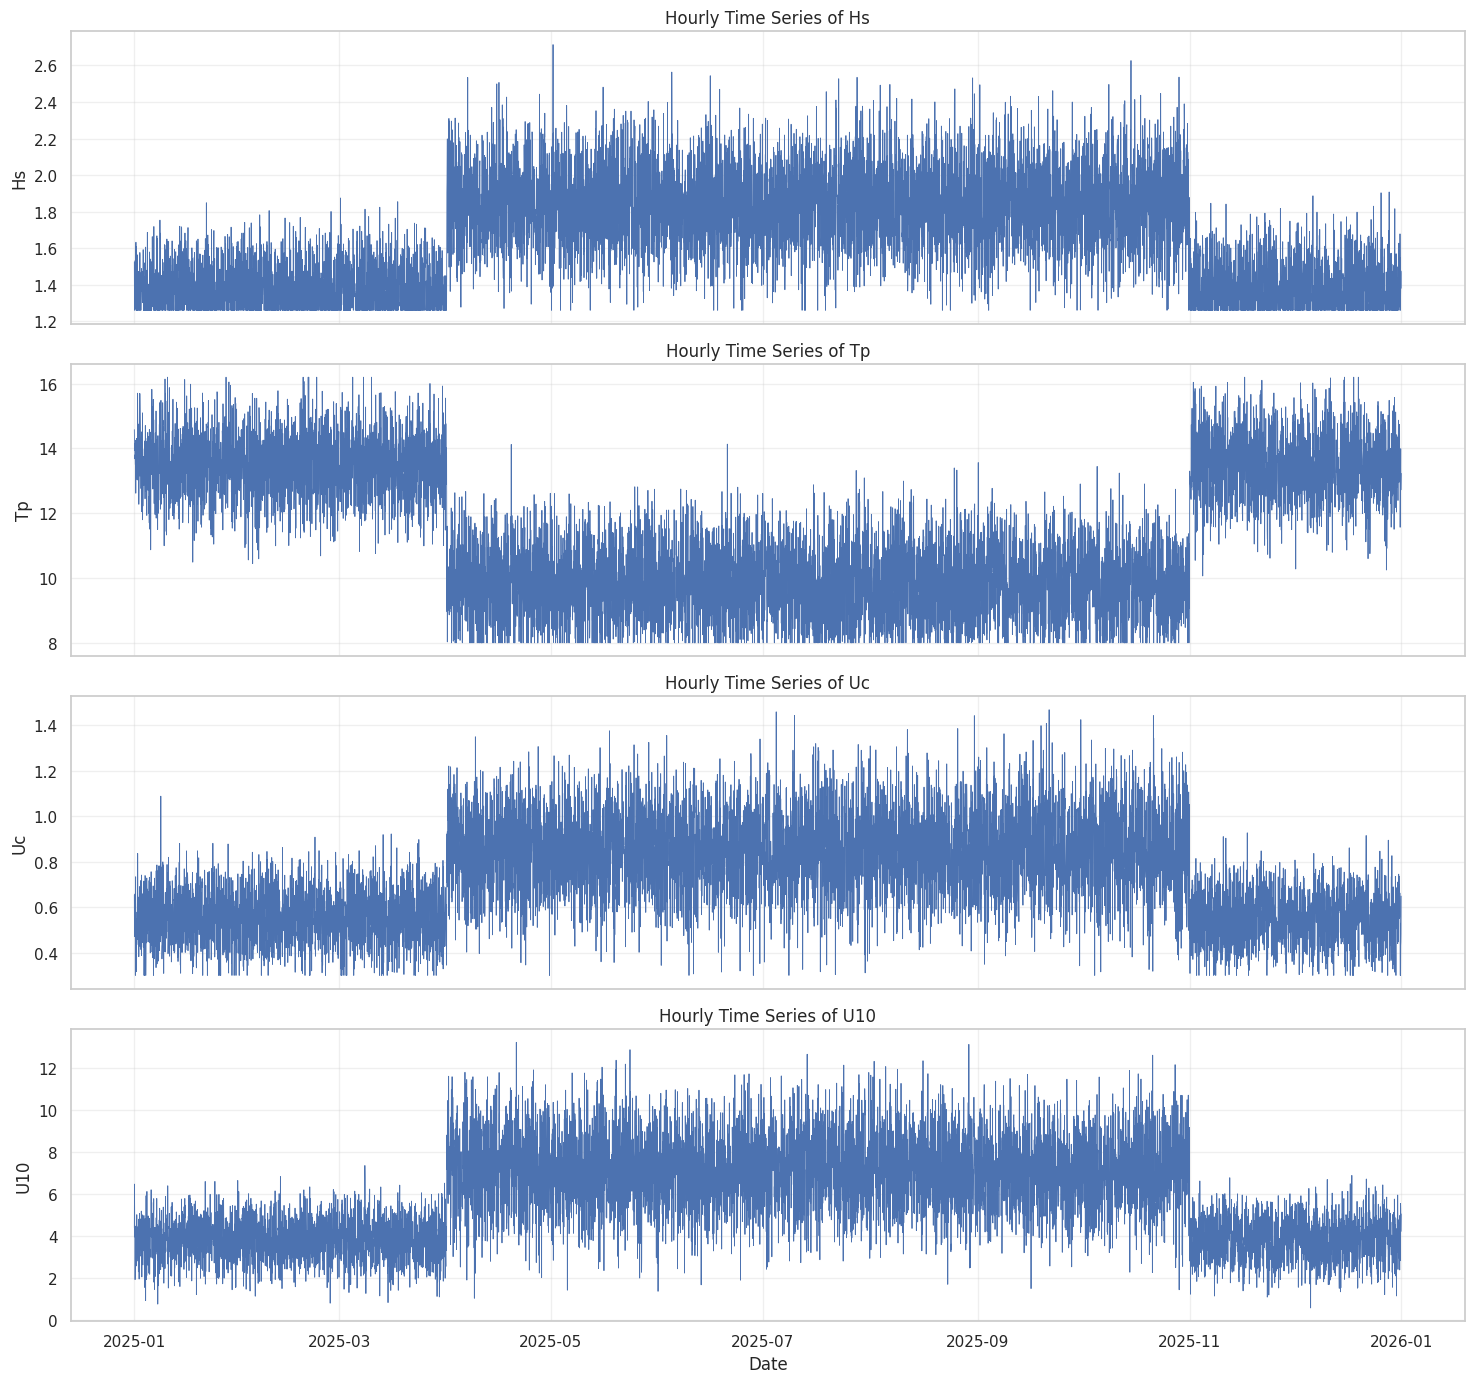

In [17]:
# Set timestamp as the index for time-series plotting
metocean_ts = df.set_index("timestamp")

# Select the key environmental variables
time_series_variables = ["Hs", "Tp", "Uc", "U10"]

# Create separate plots for each variable
fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)

for ax, variable in zip(axes, time_series_variables):

    # Plot hourly observations
    ax.plot(
        metocean_ts.index,
        metocean_ts[variable],
        linewidth=0.6
    )

    # Add titles and axis labels
    ax.set_title(f"Hourly Time Series of {variable}")
    ax.set_ylabel(variable)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

## **Seasonal Decomposition**

Seasonal decomposition separates a time series into:
- Trend component
- Seasonal component
- Residual component

For hourly metocean observations, a period of 24 is used to investigate recurring daily patterns.

The analysis is performed on significant wave height (Hs) to examine its trend, daily seasonal behaviour and unexplained variations.

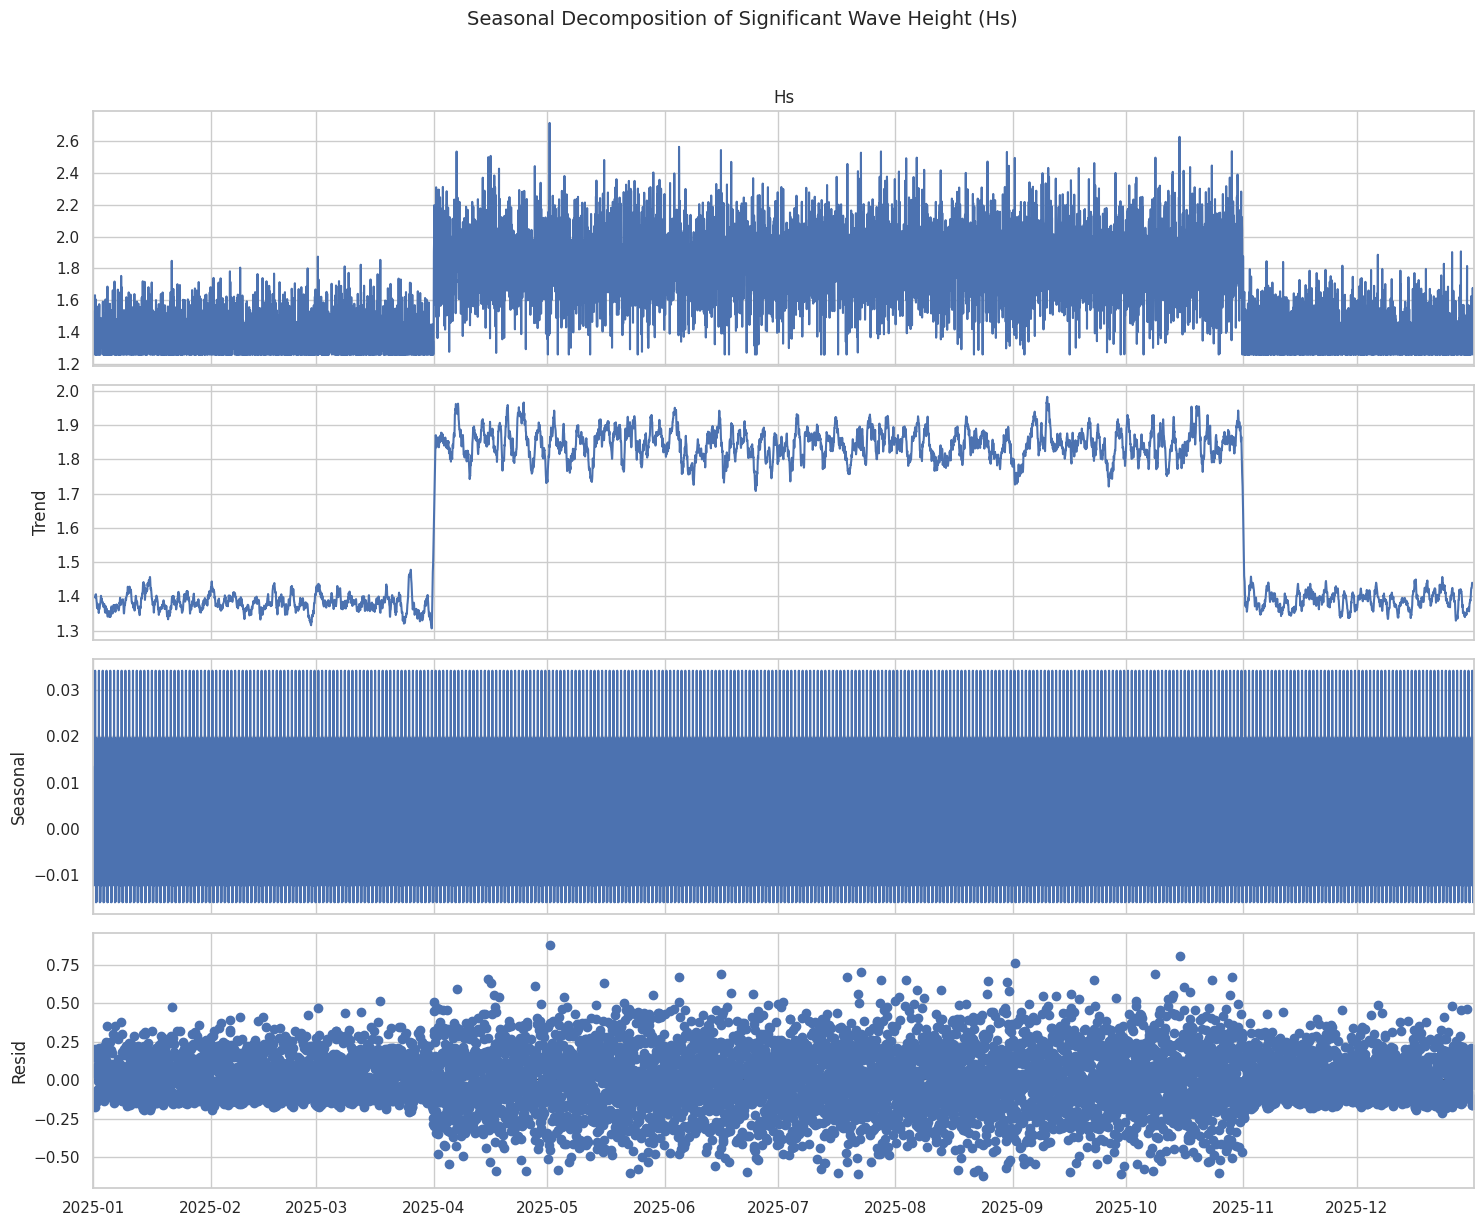

In [18]:
# Extract the Hs time series and retain the hourly timestamp index
hs_timeseries = metocean_ts["Hs"]

# Perform additive seasonal decomposition
hs_decomposition = seasonal_decompose(
    hs_timeseries,
    model="additive",
    period=24
)

# Plot the observed, trend, seasonal and residual components
fig = hs_decomposition.plot()

fig.set_size_inches(15, 12)
fig.suptitle(
    "Seasonal Decomposition of Significant Wave Height (Hs)",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

## **Hs-Tp Scatter Diagram**

The Hs-Tp scatter diagram examines the relationship between significant wave height and peak wave period.

Each point represents one hourly sea-state observation.

The plot helps identify:
- The distribution of observed sea states.
- Combinations of wave height and wave period.
- Whether higher waves tend to occur with longer or shorter wave periods.

This relationship is relevant to offshore structural response and environmental loading assessments.

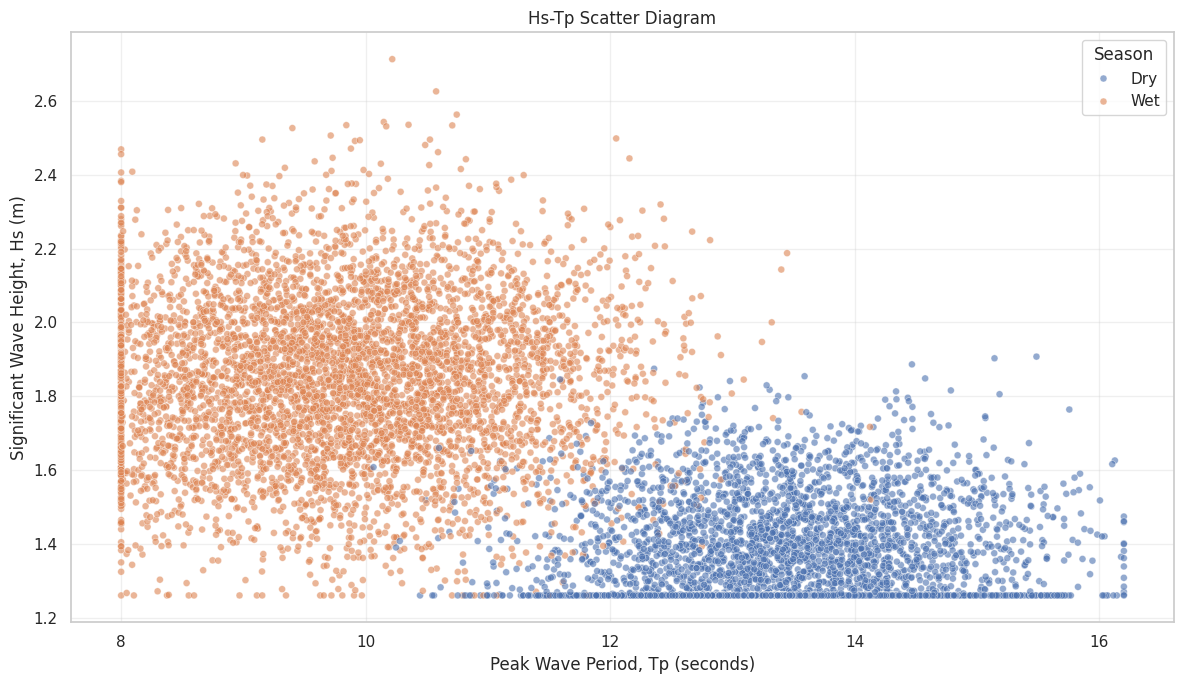

In [19]:
# Create the Hs-Tp scatter diagram
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Tp",
    y="Hs",
    hue="season",
    alpha=0.6,
    s=25
)

# Add plot labels and title
plt.title("Hs-Tp Scatter Diagram")
plt.xlabel("Peak Wave Period, Tp (seconds)")
plt.ylabel("Significant Wave Height, Hs (m)")

plt.grid(alpha=0.3)
plt.legend(title="Season")
plt.tight_layout()
plt.show()

## **Current Rose Diagram**

A current rose diagram illustrates the frequency distribution of ocean current directions and speeds.

The current direction (CD) is divided into 16 directional sectors, while current speed (Uc) is grouped into four classes.

The resulting polar diagram provides an overview of the prevailing current directions and the frequency of different current-speed ranges.

This information is relevant to the assessment of hydrodynamic loading on subsea infrastructure.

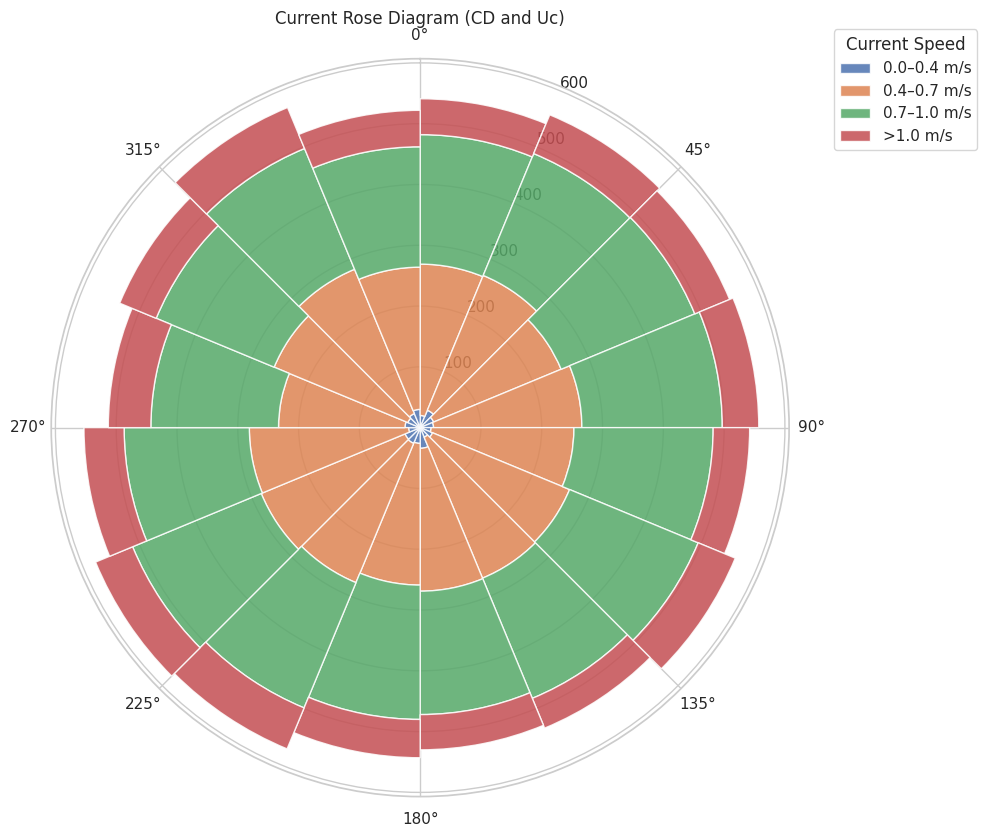

In [20]:
# Define directional sectors (16 compass sectors)
direction_bins = np.arange(0, 360 + 22.5, 22.5)

# Define current-speed classes in m/s
speed_bins = [0, 0.4, 0.7, 1.0, np.inf]

speed_labels = [
    "0.0–0.4 m/s",
    "0.4–0.7 m/s",
    "0.7–1.0 m/s",
    ">1.0 m/s"
]

# Assign each observation to a direction sector and speed class
direction_index = pd.cut(
    df["CD"] % 360,
    bins=direction_bins,
    labels=False,
    include_lowest=True
)

speed_index = pd.cut(
    df["Uc"],
    bins=speed_bins,
    labels=False,
    include_lowest=True
)

# Calculate the frequency of observations in each sector and speed class
rose_data = pd.crosstab(
    direction_index,
    speed_index
).reindex(
    index=range(16),
    columns=range(4),
    fill_value=0
)

# Set up the polar plot
fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"projection": "polar"}
)

# Convert sector centres to radians
direction_centres = np.deg2rad(
    direction_bins[:-1] + 11.25
)

# Width of each directional sector
bar_width = np.deg2rad(22.5)

# Plot stacked bars for each current-speed class
bottom = np.zeros(16)

for speed_class, label in enumerate(speed_labels):

    frequencies = rose_data[speed_class].values

    ax.bar(
        direction_centres,
        frequencies,
        width=bar_width,
        bottom=bottom,
        label=label,
        alpha=0.85,
        edgecolor="white"
    )

    bottom += frequencies

# Configure compass orientation
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

# Add title and legend
ax.set_title(
    "Current Rose Diagram (CD and Uc)",
    pad=25
)

ax.legend(
    title="Current Speed",
    loc="upper left",
    bbox_to_anchor=(1.05, 1.05)
)

plt.tight_layout()
plt.show()

## **Feature Engineering**

Feature engineering involves creating additional meaningful variables from existing dataset columns.

The objective is to enrich the original hourly metocean dataset with features that may help identify temporal patterns, environmental behaviour and potential relationships relevant to offshore asset integrity.

The original observations will be retained.

### 12.1 Temporal and Calendar Features

Temporal features are extracted from the timestamp column.

These include:
- Year
- Month
- Day
- Hour
- Day of the week
- Day of the year
- Week of the year
- Quarter
- Weekend indicator

Cyclical encoding will also be applied to selected time variables to represent repeating patterns.

In [22]:
# Extract basic calendar features from the timestamp

df["year"] = df["timestamp"].dt.year

df["month"] = df["timestamp"].dt.month

df["day"] = df["timestamp"].dt.day

df["hour"] = df["timestamp"].dt.hour

df["day_of_week"] = df["timestamp"].dt.dayofweek

df["day_of_year"] = df["timestamp"].dt.dayofyear

df["week_of_year"] = df["timestamp"].dt.isocalendar().week.astype(int)

df["quarter"] = df["timestamp"].dt.quarter


# Identify weekends
# Monday = 0 and Sunday = 6

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)


# Identify the beginning and end of each month

df["is_month_start"] = (
    df["timestamp"].dt.is_month_start
).astype(int)

df["is_month_end"] = (
    df["timestamp"].dt.is_month_end
).astype(int)


# Cyclical encoding of month
# This represents the repeating nature of the 12-month calendar

df["month_sin"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["month"] / 12
)


# Cyclical encoding of hour
# This represents the repeating 24-hour daily cycle

df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)


# Cyclical encoding of day of the year

df["day_of_year_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365
)

df["day_of_year_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365
)


# Encode the existing seasonal classification
# Dry = 1, Wet = 0

df["is_dry_season"] = (
    df["season"].str.lower() == "dry"
).astype(int)

In [23]:
# Display the original timestamp and selected new temporal features

temporal_features = [
    "timestamp",
    "year",
    "month",
    "day",
    "hour",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
    "is_dry_season"
]

df[temporal_features].head(10)

,timestamp,year,month,day,hour,day_of_week,day_of_year,week_of_year,quarter,is_weekend,month_sin,month_cos,hour_sin,hour_cos,is_dry_season
0,2025-01-01 00:00:00,2025,1,1,0,2,1,1,1,0,0.5,0.866025,0.000000,1.000000e+00,1
1,2025-01-01 01:00:00,2025,1,1,1,2,1,1,1,0,0.5,0.866025,0.258819,9.659258e-01,1
2,2025-01-01 02:00:00,2025,1,1,2,2,1,1,1,0,0.5,0.866025,0.500000,8.660254e-01,1
3,2025-01-01 03:00:00,2025,1,1,3,2,1,1,1,0,0.5,0.866025,0.707107,7.071068e-01,1
4,2025-01-01 04:00:00,2025,1,1,4,2,1,1,1,0,0.5,0.866025,0.866025,5.000000e-01,1
5,2025-01-01 05:00:00,2025,1,1,5,2,1,1,1,0,0.5,0.866025,0.965926,2.588190e-01,1
6,2025-01-01 06:00:00,2025,1,1,6,2,1,1,1,0,0.5,0.866025,1.000000,6.123234e-17,1
7,2025-01-01 07:00:00,2025,1,1,7,2,1,1,1,0,0.5,0.866025,0.965926,-2.588190e-01,1
8,2025-01-01 08:00:00,2025,1,1,8,2,1,1,1,0,0.5,0.866025,0.866025,-5.000000e-01,1
9,2025-01-01 09:00:00,2025,1,1,9,2,1,1,1,0,0.5,0.866025,0.707107,-7.071068e-01,1


## **Rolling Statistical Features**

Rolling statistical features summarise environmental conditions over a moving time window.

For this exercise, rolling means and standard deviations will be calculated over 3-hour, 6-hour, 12-hour and 24-hour windows.

The selected variables are:
- Significant wave height (Hs)
- Peak wave period (Tp)
- Current speed (Uc)
- Wind speed (U10)

The rolling mean describes the average environmental condition over the selected window, while the rolling standard deviation describes its variability.

A minimum of two observations is required to calculate each rolling statistic.

In [24]:
# Define the environmental variables for rolling calculations
rolling_variables = ["Hs", "Tp", "Uc", "U10"]

# Define rolling window sizes in hours
rolling_windows = [3, 6, 12, 24]

# Calculate rolling mean and standard deviation
for variable in rolling_variables:

    for window in rolling_windows:

        # Rolling average
        df[f"{variable}_rolling_mean_{window}h"] = (
            df[variable]
            .rolling(window=window, min_periods=2)
            .mean()
        )

        # Rolling standard deviation
        df[f"{variable}_rolling_std_{window}h"] = (
            df[variable]
            .rolling(window=window, min_periods=2)
            .std()
        )

# **Inspect the rolling features**

In [25]:
# Display selected original and rolling features
rolling_columns = [
    "timestamp",
    "Hs",
    "Hs_rolling_mean_3h",
    "Hs_rolling_std_3h",
    "Hs_rolling_mean_6h",
    "Hs_rolling_std_6h",
    "Uc",
    "Uc_rolling_mean_3h",
    "Uc_rolling_std_3h"
]

df[rolling_columns].head(10)

,timestamp,Hs,Hs_rolling_mean_3h,Hs_rolling_std_3h,Hs_rolling_mean_6h,Hs_rolling_std_6h,Uc,Uc_rolling_mean_3h,Uc_rolling_std_3h
0,2025-01-01 00:00:00,1.524854,NaN,NaN,NaN,NaN,0.653218,NaN,NaN
1,2025-01-01 01:00:00,1.260000,1.392427,0.187280,1.392427,0.187280,0.470964,0.562091,0.128873
2,2025-01-01 02:00:00,1.260000,1.348285,0.152914,1.348285,0.152914,0.575957,0.566713,0.091478
3,2025-01-01 03:00:00,1.454204,1.324735,0.112124,1.374764,0.135621,0.563988,0.536970,0.057475
4,2025-01-01 04:00:00,1.338419,1.350874,0.097699,1.367495,0.118571,0.639553,0.593166,0.040616
5,2025-01-01 05:00:00,1.268069,1.353564,0.093987,1.350924,0.113555,0.658095,0.620545,0.049850
6,2025-01-01 06:00:00,1.532813,1.379767,0.137130,1.352251,0.116013,0.633284,0.643644,0.012901
7,2025-01-01 07:00:00,1.383743,1.394875,0.132723,1.372875,0.106981,0.300000,0.530460,0.199969
8,2025-01-01 08:00:00,1.359442,1.425333,0.093870,1.389448,0.092754,0.693298,0.542194,0.211882
9,2025-01-01 09:00:00,1.490369,1.411185,0.069644,1.395476,0.098783,0.733277,0.575525,0.239447


### **Cumulative Statistical Features**

Cumulative features describe how environmental measurements develop over the observation period.

For significant wave height (Hs), current speed (Uc) and wind speed (U10), we calculate:

- Cumulative sum
- Cumulative mean
- Cumulative standard deviation
- Cumulative maximum

These features provide information about accumulated environmental exposure, average conditions, variability and the highest values observed up to each timestamp.

Note: Cumulative sums are descriptive exposure indicators. They are not direct measurements of fatigue damage or structural degradation.

In [26]:
# Select variables for cumulative feature engineering
cumulative_variables = ["Hs", "Uc", "U10"]

# Calculate cumulative statistics for each variable
for variable in cumulative_variables:

    # Running total from the beginning of the dataset
    df[f"{variable}_cumulative_sum"] = (
        df[variable].cumsum()
    )

    # Running average
    df[f"{variable}_cumulative_mean"] = (
        df[variable].expanding().mean()
    )

    # Running standard deviation
    df[f"{variable}_cumulative_std"] = (
        df[variable].expanding().std()
    )

    # Highest value observed up to the current timestamp
    df[f"{variable}_cumulative_max"] = (
        df[variable].cummax()
    )

### **Cumulative High-Condition Counts**

The 90th percentile is used to identify relatively high observations within the dataset.

For Hs, Uc and U10, we will:
1. Calculate the 90th percentile threshold.
2. Identify observations above that threshold.
3. Calculate the cumulative number of exceedances.

These features describe the frequency of relatively high environmental conditions over time.

The thresholds are dataset-specific statistical thresholds, not engineering design limits.

In [28]:
# Calculate cumulative counts of observations above the 90th percentile

for variable in cumulative_variables:

    # Calculate the dataset-specific 90th percentile
    threshold = df[variable].quantile(0.90)

    # Identify observations exceeding the threshold
    exceedance = (df[variable] > threshold).astype(int)

    # Count exceedances cumulatively
    df[f"{variable}_cumulative_exceedance_count"] = (
        exceedance.cumsum()
    )

    # Display the threshold used
    print(f"{variable} 90th percentile: {threshold:.4f}")

Hs 90th percentile: 2.0589
Uc 90th percentile: 1.0202
U10 90th percentile: 8.8523


## **Enriched Dataset Validation**

This section verifies that feature engineering was completed successfully.

We will:
- Check the total number of observations and columns.
- Confirm that all original columns are retained.
- Count the newly engineered features.
- Check missing values introduced by rolling calculations.
- Confirm that the dataset remains chronologically ordered.

The expected output is 8,760 observations and 74 columns.

In [29]:
# Check the dimensions of the enriched dataset
print("Enriched Dataset Shape:", df.shape)

# Identify the original dataset columns
original_columns = [
    "timestamp", "Hs", "season", "Tp", "MWD",
    "Uc", "CD", "U10", "SST", "d"
]

# Identify newly engineered features
new_features = [
    column for column in df.columns
    if column not in original_columns
]

# Display feature counts
print("\nOriginal Columns:", len(original_columns))
print("Newly Engineered Features:", len(new_features))
print("Total Columns:", len(df.columns))

# Confirm that all original columns remain
print(
    "\nAll original columns retained:",
    all(column in df.columns for column in original_columns)
)

# Check missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check chronological order
print(
    "Chronologically Ordered:",
    df["timestamp"].is_monotonic_increasing
)

Enriched Dataset Shape: (8760, 75)

Original Columns: 10
Newly Engineered Features: 65
Total Columns: 75

All original columns retained: True

Total Missing Values: 35
Chronologically Ordered: True


In [30]:
# Display columns containing missing values
missing_summary = df.isnull().sum()

missing_summary = missing_summary[
    missing_summary > 0
].sort_values(ascending=False)

missing_summary

,0
Hs_rolling_mean_3h,1
Hs_rolling_std_3h,1
Hs_rolling_mean_6h,1
Hs_rolling_std_6h,1
Hs_rolling_mean_12h,1
Hs_rolling_std_12h,1
Hs_rolling_mean_24h,1
Hs_rolling_std_24h,1
Tp_rolling_mean_3h,1
Tp_rolling_std_3h,1


In [31]:
# Confirm the final enriched dataset dimensions
print("Dataset shape:", df.shape)

# Count engineered features
print("Engineered features:", len(new_features))

# Confirm the number of original observations
print("Number of observations:", len(df))

# Confirm original columns are retained
print("Original columns retained:",
      all(col in df.columns for col in original_columns))

Dataset shape: (8760, 75)
Engineered features: 65
Number of observations: 8760
Original columns retained: True


## **Exporting the Enriched Dataset**

The enriched dataset contains the original hourly metocean observations and 65 additional engineered features.

It will be exported as a CSV file for submission and version control.

The exported file will retain all 8,760 observations and 75 columns.

In [32]:
# Define the output filename
output_file = "Jubilee_TRP3_Metocean_Enriched.csv"

# Export the enriched dataset
df.to_csv(output_file, index=False)

# Confirm successful export
print(f"Enriched dataset exported successfully: {output_file}")

Enriched dataset exported successfully: Jubilee_TRP3_Metocean_Enriched.csv
